In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

In [42]:
path = "../../Processed_data/"
files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")

Z_range = np.linspace(50.0, 50.8, 11)
X_range = np.linspace(41.4, 41.7, 21)

map_plot_x = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = np.round(float(filename.split("Xpos")[1].split("00000.root")[0]), 3)
    z_pos = np.round(float(filename.split("Zpos")[1].split("_")[0])         , 3)
    map_plot_x.append(x_pos)
    map_plot_z.append(z_pos)

# plt.scatter(map_plot_x, map_plot_z)
# plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    # 't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.16_Xpos41.6400000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.16_Xpos41.5800000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.08_Xpos41.56500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.0_Xpos41.68500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.0_Xpos41.6100000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.08_Xpos41.6400000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.0_Xpos41.56500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.16_Xpos41.68500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.08_Xpos41.50500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50.0_Xpos41.5500000.root
proc_F_AC_LGAD_40um_strip_NEv2000_BV115000mV_Laser20pc_Temp16C_Zpos50

# Read and store specific branches.

In [15]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_50.16_41.64', 'pos_50.16_41.58', 'pos_50.08_41.565', 'pos_50.0_41.685', 'pos_50.0_41.61', 'pos_50.08_41.64', 'pos_50.0_41.565', 'pos_50.16_41.685', 'pos_50.08_41.505', 'pos_50.0_41.55', 'pos_50.16_41.445', 'pos_50.0_41.625', 'pos_50.08_41.685', 'pos_50.0_41.535', 'pos_50.0_41.67', 'pos_50.16_41.565', 'pos_50.16_41.61', 'pos_50.08_41.58', 'pos_50.16_41.49', 'pos_50.08_41.445', 'pos_50.0_41.505', 'pos_50.0_41.4', 'pos_50.16_41.625', 'pos_50.24_41.4', 'pos_50.08_41.625', 'pos_50.08_41.49', 'pos_50.16_41.52', 'pos_50.0_41.445', 'pos_50.16_41.55', 'pos_50.08_41.535', 'pos_50.08_41.595', 'pos_50.16_41.46', 'pos_50.0_41.475', 'pos_50.0_41.43', 'pos_50.16_41.7', 'pos_50.0_41.46', 'pos_50.08_41.415', 'pos_50.16_41.535', 'pos_50.0_41.64', 'pos_50.16_41.43', 'pos_50.16_41.415', 'pos_50.0_41.52', 'pos_50.0_41.595', 'pos_50.16_41.475', 'pos_50.0_41.49', 'pos_50.08_41.52', 'pos_50.08_41.43', 'pos_50.16_41.505', 'pos_50.24_41.415', 'pos_50.16_41.4', 'pos_50.0_41.7', 'pos_50.08_41.61',

## Amplitude and NEvents vs z position.

pos_50.16_41.64
pos_50.16_41.58
pos_50.16_41.565
pos_50.16_41.685
pos_50.16_41.61
pos_50.16_41.64
pos_50.16_41.565
pos_50.16_41.685
pos_50.16_41.505
pos_50.16_41.55
pos_50.16_41.445
pos_50.16_41.625
pos_50.16_41.685
pos_50.16_41.535
pos_50.16_41.67
pos_50.16_41.565
pos_50.16_41.61
pos_50.16_41.58
pos_50.16_41.49
pos_50.16_41.445
pos_50.16_41.505
pos_50.16_41.64
pos_50.16_41.58
pos_50.16_41.565
pos_50.16_41.685
pos_50.16_41.61
pos_50.16_41.64
pos_50.16_41.565
pos_50.16_41.685
pos_50.16_41.505
pos_50.16_41.55
pos_50.16_41.445
pos_50.16_41.625
pos_50.16_41.685
pos_50.16_41.535
pos_50.16_41.67
pos_50.16_41.565
pos_50.16_41.61
pos_50.16_41.58
pos_50.16_41.49
pos_50.16_41.445
pos_50.16_41.505
pos_50.08_41.64
pos_50.08_41.58
pos_50.08_41.565
pos_50.08_41.685
pos_50.08_41.61
pos_50.08_41.64
pos_50.08_41.565
pos_50.08_41.685
pos_50.08_41.505
pos_50.08_41.55
pos_50.08_41.445
pos_50.08_41.625
pos_50.08_41.685
pos_50.08_41.535
pos_50.08_41.67
pos_50.08_41.565
pos_50.08_41.61
pos_50.08_41.58
pos_50

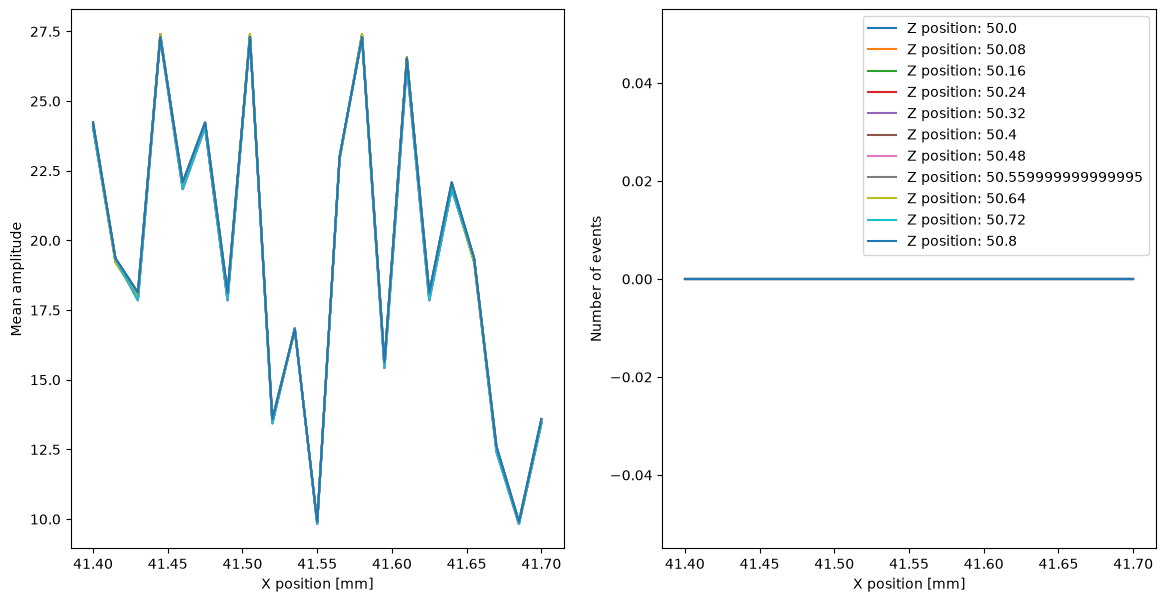

In [27]:
cols = 2
rows = 1
size = 7

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))

for z_i, z in enumerate(Z_range):
    mean_amps = []
    n_events = []
    for x_i, x in enumerate(X_range):
        # print(z, x)
        l = f"pos_{map_plot_z[z_i]}_{map_plot_x[x_i]}"
        print(l)
        mean_amps.append(np.mean(amp[l][:,0]))
        n_events.append(np.sum(timestamps[l][:,0]>0))
    ax[0].plot(X_range, mean_amps, label = f"Z position: {z}")
    ax[0].set_xlabel("X position [mm]")
    ax[0].set_ylabel("Mean amplitude")

    ax[1].plot(X_range, n_events, label = f"Z position: {z}")
    ax[1].set_xlabel("X position [mm]")
    ax[1].set_ylabel("Number of events")

    plt.legend()

In [41]:
for i in timestamps.keys():
    print(timestamps[i][:,])

[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 21.1, 0]]
[[0, 0, 0, 0, 0, 0, 21.2, 0], [0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ..., 21.3, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 23, 0]]
[[0, 0, 0, 0, 0, 0, 22.9, 0], [0, 0, ..., 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 11.4]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 22.9, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, ..., 0, 0], ..., [0, 0, 0, 0, 0, 0, 0, 0]]
[[0, 0, 0, 0, 0, 0, 0, 0], [0, 0, ..., 0, 